<a href="https://colab.research.google.com/github/andres-merino/AprendizajeAutomaticoInicial-05-N0105/blob/main/2-Ejercicios/05-kNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<table style="border: none; border-collapse: collapse;">
    <tr>
        <td style="width: 20%; vertical-align: middle; padding-right: 10px;">
            <img src="https://i.imgur.com/nt7hloA.png" width="100">
        </td>
        <td style="width: 2px; text-align: center;">
            <font color="#0030A1" size="7">|</font><br>
            <font color="#0030A1" size="7">|</font>
        </td>
        <td>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="5">
                <b>Facultad de Ciencias Exactas, Naturales y Ambientales</b>
            </font> </p>
            <p style="font-variant: small-caps;"><font color="#0030A1" size="4">
                Aprendizaje Automático Inicial &bull; Algoritmo k-Nearest Neighbors
            </font></p>
            <p style="font-style: oblique;"><font color="#0030A1" size="3">
                Andrés Merino &bull; Periodo 2026-2
            </font></p>
        </td>  
    </tr>
</table>

---
## <font color='264CC7'> Introducción </font>

A lo largo de este taller, aplicaremos el algoritmo de clasificación k-Nearest Neighbors (kNN) para predecir la clase de un conjunto de datos y también para predecir valores numéricos.

Los paquetes necesarios son:

In [1]:
# Paquetes necesarios
import numpy as np
import pandas as pd  # Manejo de datos
import matplotlib.pyplot as plt  # Visualización

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder  # Estandarización y codificación
from sklearn.model_selection import train_test_split # División de datos
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
from sklearn.metrics import mean_squared_error, r2_score

# Algoritmo k-NN
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor

---
## <font color='264CC7'> Clasificación </font>


### <font color='264CC7'> Preprocesamiento de datos </font>

Primero necesitas el conjunto de datos. Usa el conjunto de datos seleccionado en las primeras semanas.

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Carga el conjunto de datos y procésalos:
<ul>
  <li>Muestra algunos datos.</li>
  <li>Muestra una descripción de los datos.</li>
  <li>Define predictores y objetivo, excluyendo información que revele la respuesta.</li>
  <li>Reserva prueba y divide el resto en entrenamiento y validación con semillas registradas; estratifica si se trata de clasificación y los tamaños de clase lo permiten.</li>
  <li>Ajusta imputación, codificación y escalado solo con entrenamiento; transforma validación sin reajustar.</li>
</ul>
</div>

In [2]:
# Treamos nuestro conjunto de datos
url = 'https://raw.githubusercontent.com/juanfercaicedo/AprendizajeAutomaticoInicial/refs/heads/main/Dataset/futbollStats.csv'
# Panda lee el conjunto de datos
data = pd.read_csv(url)

print(data.head())
print(data.info())

   ranking_influencia            jugador nacionalidad confederacion  \
0                   1       Lionel Messi    Argentina      CONMEBOL   
1                   2  Cristiano Ronaldo     Portugal          UEFA   
2                   3    Zinedine Zidane      Francia          UEFA   
3                   4  Ronaldinho Gaúcho       Brasil      CONMEBOL   
4                   5     Andrés Iniesta       España          UEFA   

       posicion_principal         posicion_base      rol_campo  \
0  Delantero / Mediapunta             Delantero      Delantero   
1     Delantero / Extremo             Delantero      Delantero   
2    Mediocentro Ofensivo  Mediocentro Ofensivo  Mediocampista   
3    Extremo / Mediapunta               Extremo      Delantero   
4             Mediocentro           Mediocentro  Mediocampista   

  periodo_activo_siglo_xxi                                clubes_emblematicos  \
0                2004-2026                   FC Barcelona / PSG / Inter Miami   
1             


### <font color='264CC7'> Determinación del valor de k </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Determina el número óptimo de k para el algoritmo kNN:
<ul>
  <li>Genera una gráfica que muestre el valor de k frente a la exactitud (accuracy) de entrenamiento y validación.</li>
  <li>Selecciona el valor de k que maximice la exactitud de validación, sin consultar prueba.</li>
</ul>
</div>


In [3]:
target_clf = 'rol_campo'
drop_cols_clf = [
    target_clf, 'jugador', 'clubes_emblematicos',
    'legado_e_influencia', 'periodo_activo_siglo_xxi',
    'posicion_principal', 'posicion_base',
    'rol_Portero', 'rol_Defensa', 'rol_Mediocampista', 'rol_Delantero'
]

X_clf = data.drop(columns=drop_cols_clf)
y_clf = data[target_clf]

print('Resumen de los predictores:')
display(X_clf.describe(include='all').T)
print('Distribución de clases:')
print(y_clf.value_counts())

SEED_PRUEBA = 42
SEED_VALIDACION = 21

X_temp_clf, X_test_clf, y_temp_clf, y_test_clf = train_test_split(
    X_clf, y_clf, test_size=0.20,
    random_state=SEED_PRUEBA, stratify=y_clf
)
X_train_clf, X_val_clf, y_train_clf, y_val_clf = train_test_split(
    X_temp_clf, y_temp_clf, test_size=0.25,
    random_state=SEED_VALIDACION, stratify=y_temp_clf
)

print('Tamanos:', len(X_train_clf), len(X_val_clf), len(X_test_clf))

numeric_clf = X_clf.select_dtypes(include=np.number).columns.tolist()
categorical_clf = X_clf.select_dtypes(exclude=np.number).columns.tolist()

preprocessor_clf = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_clf),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_clf)
])


Resumen de los predictores:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
ranking_influencia,233.0,NaN,NaN,NaN,117.0,67.405489,1.0,59.0,117.0,175.0,233.0
nacionalidad,233,48,España,29,NaN,NaN,NaN,NaN,NaN,NaN,NaN
confederacion,233,5,UEFA,154,NaN,NaN,NaN,NaN,NaN,NaN,NaN
anio_inicio,233.0,NaN,NaN,NaN,2006.343348,6.25208,2000.0,2000.0,2005.0,2011.0,2023.0
anio_fin,233.0,NaN,NaN,NaN,2021.712446,5.645312,2005.0,2018.0,2026.0,2026.0,2026.0
anios_activos,233.0,NaN,NaN,NaN,16.369099,4.565735,4.0,13.0,17.0,20.0,25.0
num_clubes,233.0,NaN,NaN,NaN,3.330472,1.132501,1.0,3.0,3.0,4.0,7.0
partidos_jugados,233.0,NaN,NaN,NaN,638.630901,200.264914,164.0,512.0,642.0,765.0,1343.0
minutos_jugados,233.0,NaN,NaN,NaN,51547.48927,16845.507877,12852.0,39036.0,51554.0,61579.0,113998.0
minutos_por_partido,233.0,NaN,NaN,NaN,80.509442,4.486874,65.28,77.75,80.67,83.62,89.8


Distribución de clases:
rol_campo
Mediocampista    89
Delantero        79
Defensa          48
Portero          17
Name: count, dtype: int64
Tamanos: 139 47 47


Semilla de validacion: 21
k seleccionado: 3
Exactitud maxima de validacion: 0.7872340425531915


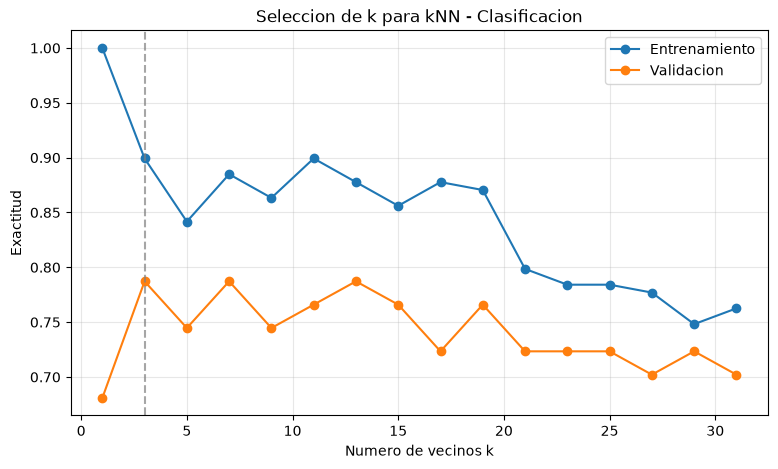

In [4]:
X_train_t_clf = preprocessor_clf.fit_transform(X_train_clf)
X_val_t_clf = preprocessor_clf.transform(X_val_clf)

k_values = list(range(1, 32, 2))
train_accuracy = []
val_accuracy = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_t_clf, y_train_clf)
    train_accuracy.append(accuracy_score(y_train_clf, model.predict(X_train_t_clf)))
    val_accuracy.append(accuracy_score(y_val_clf, model.predict(X_val_t_clf)))

best_k_clf = k_values[int(np.argmax(val_accuracy))]
print('Semilla de validacion:', SEED_VALIDACION)
print('k seleccionado:', best_k_clf)
print('Exactitud maxima de validacion:', max(val_accuracy))

plt.figure(figsize=(9, 5))
plt.plot(k_values, train_accuracy, marker='o', label='Entrenamiento')
plt.plot(k_values, val_accuracy, marker='o', label='Validacion')
plt.axvline(best_k_clf, color='gray', linestyle='--', alpha=0.7)
plt.xlabel('Numero de vecinos k')
plt.ylabel('Exactitud')
plt.title('Seleccion de k para kNN - Clasificacion')
plt.legend()
plt.grid(alpha=0.3)
plt.show()



### <font color='264CC7'> Entrenamiento del modelo y evaluación </font>


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Entrena el modelo y evalúalo:
<ul>
  <li>Fija el valor de k seleccionado y reajusta las transformaciones y el modelo con entrenamiento y validación.</li>
  <li>Evalúa una sola vez en la prueba reservada, sin usarla para volver a ajustar.</li>
  <li>Genera una matriz de confusión y muestra las métricas de evaluación.</li>
</ul>
</div>

Exactitud del modelo (accuracy): 0.74
Matriz de confusion:
[[ 6  0  4  0]
 [ 0 13  3  0]
 [ 1  3 14  0]
 [ 1  0  0  2]]
Reporte de clasificacion:
               precision    recall  f1-score   support

      Defensa       0.75      0.60      0.67        10
    Delantero       0.81      0.81      0.81        16
Mediocampista       0.67      0.78      0.72        18
      Portero       1.00      0.67      0.80         3

     accuracy                           0.74        47
    macro avg       0.81      0.71      0.75        47
 weighted avg       0.76      0.74      0.74        47



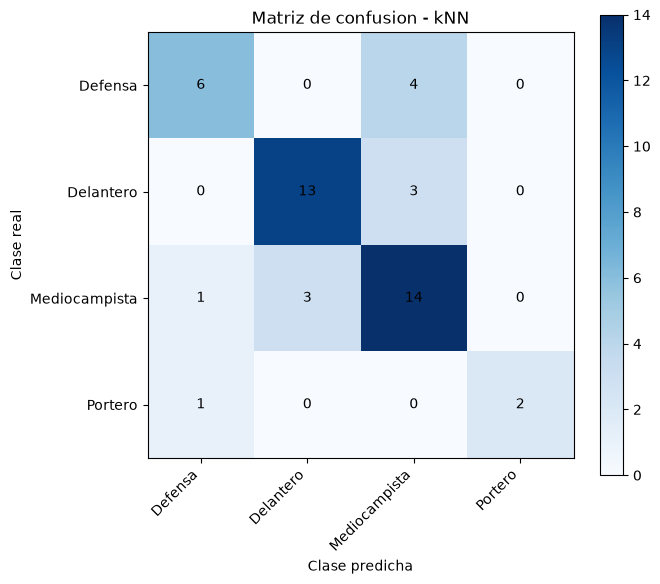

In [5]:
X_fit_clf = pd.concat([X_train_clf, X_val_clf])
y_fit_clf = pd.concat([y_train_clf, y_val_clf])

# Crear y entrenar el modelo con el k seleccionado
modelo_clf = Pipeline([
    ('preprocessing', preprocessor_clf),
    ('knn', KNeighborsClassifier(n_neighbors=best_k_clf))
])
modelo_clf.fit(X_fit_clf, y_fit_clf)

# Realizar predicciones y evaluar una sola vez en prueba
y_pred = modelo_clf.predict(X_test_clf)

accuracy = round(accuracy_score(y_test_clf, y_pred), 2)
print('Exactitud del modelo (accuracy):', accuracy)

cm = confusion_matrix(y_test_clf, y_pred)
print('Matriz de confusion:')
print(cm)

print('Reporte de clasificacion:')
print(classification_report(y_test_clf, y_pred))

labels = sorted(y_test_clf.unique())
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(len(labels)), labels=labels, rotation=45, ha='right')
ax.set_yticks(range(len(labels)), labels=labels)
ax.set_xlabel('Clase predicha')
ax.set_ylabel('Clase real')
ax.set_title('Matriz de confusion - kNN')
for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, cm[i, j], ha='center', va='center')
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


---
## <font color='264CC7'> Regresión </font>


### <font color='264CC7'> Preprocesamiento de datos </font>

Primero necesitas el conjunto de datos. Usa el conjunto de datos seleccionado en las primeras semanas.

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Carga el conjunto de datos y procésalos:
<ul>
  <li>Muestra algunos datos.</li>
  <li>Muestra una descripción de los datos.</li>
  <li>Define predictores y objetivo, excluyendo información que revele la respuesta.</li>
  <li>Reserva prueba y divide el resto en entrenamiento y validación con semillas registradas; estratifica si se trata de clasificación y los tamaños de clase lo permiten.</li>
  <li>Ajusta imputación, codificación y escalado solo con entrenamiento; transforma validación sin reajustar.</li>
</ul>
</div>
Define un objetivo numérico y exclúyelo de los predictores; usa KNeighborsRegressor. Si tu base no permite plantear regresión con sentido, consulta al docente antes de cambiar de conjunto de datos.


In [6]:
target_reg = 'ranking_influencia'
drop_cols_reg = [
    target_reg, 'jugador', 'clubes_emblematicos',
    'legado_e_influencia', 'periodo_activo_siglo_xxi',
    'posicion_principal', 'posicion_base',
    'rol_Portero', 'rol_Defensa', 'rol_Mediocampista', 'rol_Delantero'
]

X_reg = data.drop(columns=drop_cols_reg)
y_reg = data[target_reg]

print('Primeros registros:')
display(pd.concat([X_reg, y_reg], axis=1).head())
print('\nDescripcion del objetivo:')
print(y_reg.describe())

X_temp_reg, X_test_reg, y_temp_reg, y_test_reg = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=SEED_PRUEBA
)
X_train_reg, X_val_reg, y_train_reg, y_val_reg = train_test_split(
    X_temp_reg, y_temp_reg, test_size=0.25, random_state=SEED_VALIDACION
)

print('Tamanos:', len(X_train_reg), len(X_val_reg), len(X_test_reg))

numeric_reg = X_reg.select_dtypes(include=np.number).columns.tolist()
categorical_reg = X_reg.select_dtypes(exclude=np.number).columns.tolist()

preprocessor_reg = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), numeric_reg),
    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore'))
    ]), categorical_reg)
])


Primeros registros:


,nacionalidad,confederacion,rol_campo,anio_inicio,anio_fin,anios_activos,num_clubes,partidos_jugados,minutos_jugados,minutos_por_partido,...,pases_exitosos_por_90,pases_clave_por_90,tarjetas_amarillas_por_90,tarjetas_rojas_por_90,conf_UEFA,conf_CONMEBOL,conf_CAF,conf_AFC,conf_CONCACAF,ranking_influencia
0,Argentina,CONMEBOL,Delantero,2004,2026,23,3,1185,98028,82.72,...,56.44,2.729,0.094,0.003,0,1,0,0,0,1
1,Portugal,UEFA,Delantero,2002,2026,25,5,1343,113998,84.88,...,35.22,1.422,0.106,0.009,1,0,0,0,0,2
2,Francia,UEFA,Mediocampista,2000,2006,7,2,318,26661,83.84,...,64.90,2.613,0.155,0.024,1,0,0,0,0,3
3,Brasil,CONMEBOL,Delantero,2000,2015,16,4,685,55116,80.46,...,49.52,2.446,0.121,0.013,0,1,0,0,0,4
4,España,UEFA,Mediocampista,2002,2024,23,2,965,75422,78.16,...,68.04,1.918,0.081,0.000,1,0,0,0,0,5



Descripcion del objetivo:
count    233.000000
mean     117.000000
std       67.405489
min        1.000000
25%       59.000000
50%      117.000000
75%      175.000000
max      233.000000
Name: ranking_influencia, dtype: float64
Tamanos: 139 47 47



### <font color='264CC7'> Determinación del valor de k </font>

<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Determina el número óptimo de k para el algoritmo kNN:
<ul>
  <li>Genera una gráfica que muestre el valor de k frente a el error cuadrático medio (MSE) de entrenamiento y validación.</li>
  <li>Selecciona el valor de k que minimice el MSE de validación, sin consultar prueba.</li>
</ul>
</div>


Semilla de validacion: 21
k seleccionado: 5
MSE minimo de validacion: 3619.371063829787


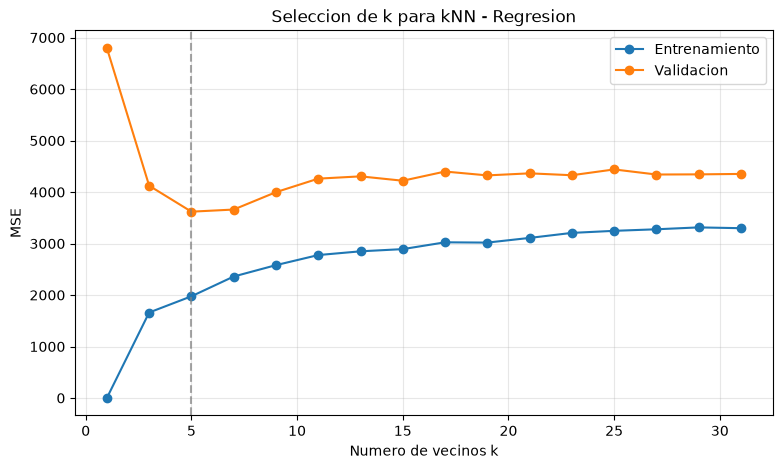

In [7]:
X_train_t_reg = preprocessor_reg.fit_transform(X_train_reg)
X_val_t_reg = preprocessor_reg.transform(X_val_reg)

k_values_reg = list(range(1, 32, 2))
train_mse = []
val_mse = []

for k in k_values_reg:
    model = KNeighborsRegressor(n_neighbors=k)
    model.fit(X_train_t_reg, y_train_reg)
    train_mse.append(mean_squared_error(y_train_reg, model.predict(X_train_t_reg)))
    val_mse.append(mean_squared_error(y_val_reg, model.predict(X_val_t_reg)))

best_k_reg = k_values_reg[int(np.argmin(val_mse))]
print('Semilla de validacion:', SEED_VALIDACION)
print('k seleccionado:', best_k_reg)
print('MSE minimo de validacion:', min(val_mse))

plt.figure(figsize=(9, 5))
plt.plot(k_values_reg, train_mse, marker='o', label='Entrenamiento')
plt.plot(k_values_reg, val_mse, marker='o', label='Validacion')
plt.axvline(best_k_reg, color='gray', linestyle='--', alpha=0.7)
plt.xlabel('Numero de vecinos k')
plt.ylabel('MSE')
plt.title('Seleccion de k para kNN - Regresion')
plt.legend()
plt.grid(alpha=0.3)
plt.show()



### <font color='264CC7'> Entrenamiento del modelo y evaluación </font>


<div style="background-color: #edf1f8; border-color: #264CC7; border-left: 5px solid #264CC7; padding: 0.5em;">
<strong>Ejercicio:</strong><br>
    Entrena el modelo y evalúalo:
<ul>
  <li>Fija el valor de k seleccionado y reajusta las transformaciones y el modelo con entrenamiento y validación.</li>
  <li>Evalúa una sola vez en la prueba reservada, sin usarla para volver a ajustar.</li>
  <li>Calcula el error cuadrático medio.</li>
</ul>
</div>

In [8]:
X_fit_reg = pd.concat([X_train_reg, X_val_reg])
y_fit_reg = pd.concat([y_train_reg, y_val_reg])

# Crear y entrenar el modelo con el k seleccionado
modelo_reg = Pipeline([
    ('preprocessing', preprocessor_reg),
    ('knn', KNeighborsRegressor(n_neighbors=best_k_reg))
])
modelo_reg.fit(X_fit_reg, y_fit_reg)

# Realizar predicciones y calcular el error en prueba
y_pred_reg = modelo_reg.predict(X_test_reg)
test_mse = mean_squared_error(y_test_reg, y_pred_reg)
test_rmse = np.sqrt(test_mse)

print('k seleccionado:', best_k_reg)
print('MSE en prueba:', test_mse)
print('RMSE en prueba:', test_rmse)
print('R2 en prueba:', r2_score(y_test_reg, y_pred_reg))


k seleccionado: 5
MSE en prueba: 4001.511489361701
RMSE en prueba: 63.257501447351686
R2 en prueba: 0.1550159880255665
